## Q1. Dataset Loading

Load the Wine Dataset using Scikit-learn and display the first 10 records, dataset shape, feature names, and target classes.

In [3]:

import pandas as pd
from sklearn.datasets import load_wine


wine = load_wine()


df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target

print(df.head(10))


   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   
5    14.20        1.76  2.45               15.2      112.0           3.27   
6    14.39        1.87  2.45               14.6       96.0           2.50   
7    14.06        2.15  2.61               17.6      121.0           2.60   
8    14.83        1.64  2.17               14.0       97.0           2.80   
9    13.86        1.35  2.27               16.0       98.0           2.98   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.

## Q2. Exploratory Data Analysis (EDA)

Perform Exploratory Data Analysis (EDA) by:

    Checking data types
    Identifying missing values
    Displaying statistical summary
    Finding duplicate records
    Displaying the class distribution

In [6]:
print(df.dtypes)

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object


In [7]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


In [8]:
df.isna().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["target"].value_counts().sort_index()


target
0    59
1    71
2    48
Name: count, dtype: int64

## Q3. Data Visualization

Create the following visualizations:

    Class Distribution Plot
    Correlation Heatmap
    Histogram of selected features
    Box Plot to identify outliers
    Write your observations for each visualization.

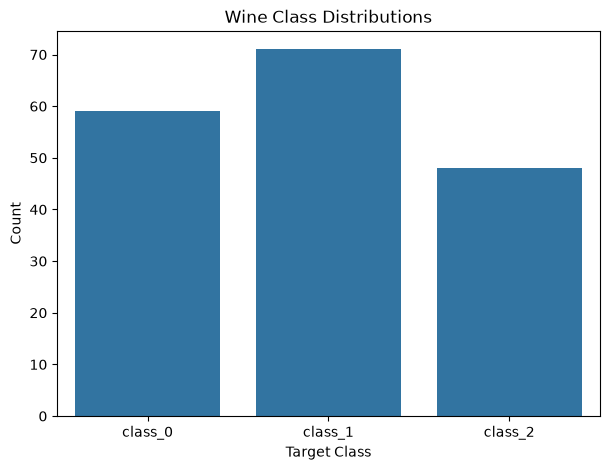

In [13]:
##Class Distribution Plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))
sns.countplot(x="target",data=df)

plt.title("Wine Class Distributions")
plt.xlabel("Target Class")
plt.ylabel("Count")
plt.xticks([0, 1, 2], wine.target_names)

plt.show()

**Observation:** The plot shows the number of records belonging to each wine class.

**2.Correlation Heatmap**

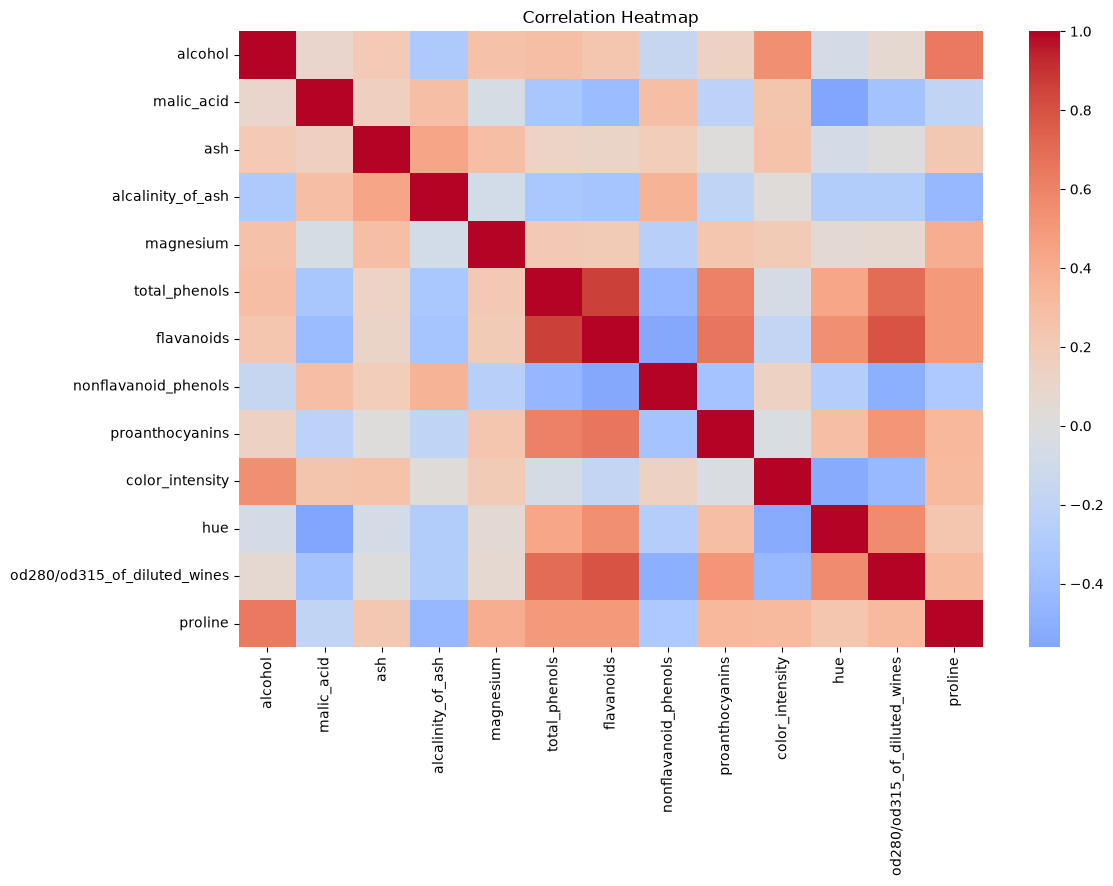

In [14]:

plt.figure(figsize=(12, 8))

correlation = df.drop(columns="target").corr()

sns.heatmap(correlation, cmap="coolwarm", center=0)

plt.title("Correlation Heatmap")
plt.show()


**Observation**: The heatmap shows the correlation between numerical features. Values closer to +1 indicate positive correlation, while values closer to -1 indicate negative correlation.

**3 Histogram of Selected Features**

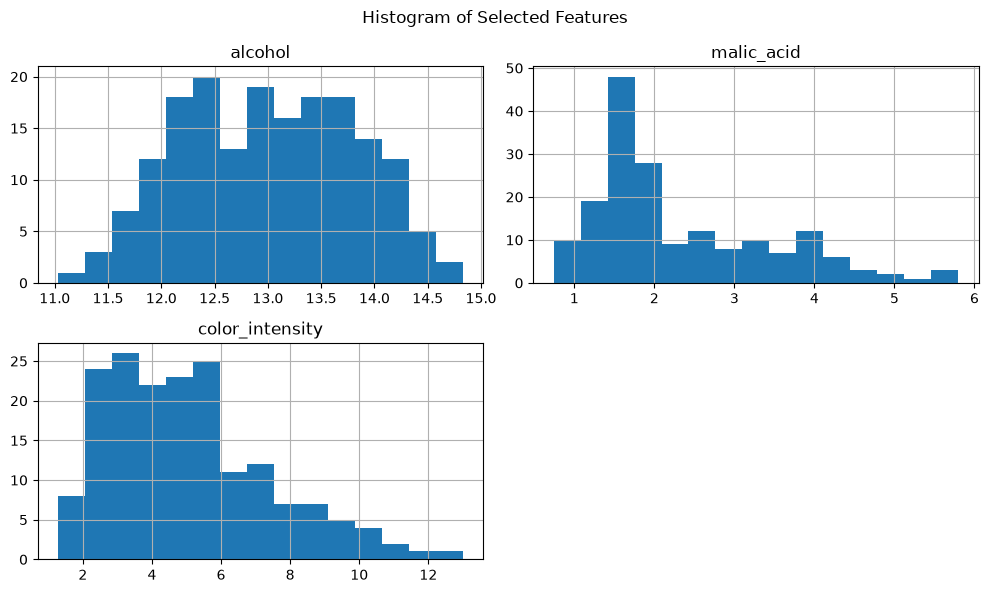

In [15]:

selected_features = [
    "alcohol",
    "malic_acid",
    "color_intensity"
]

df[selected_features].hist(figsize=(10, 6), bins=15)

plt.suptitle("Histogram of Selected Features")
plt.tight_layout()
plt.show()


**Observation:** Histograms show the distribution and spread of the selected features.

**4 Box Plot to Identify Outliers**

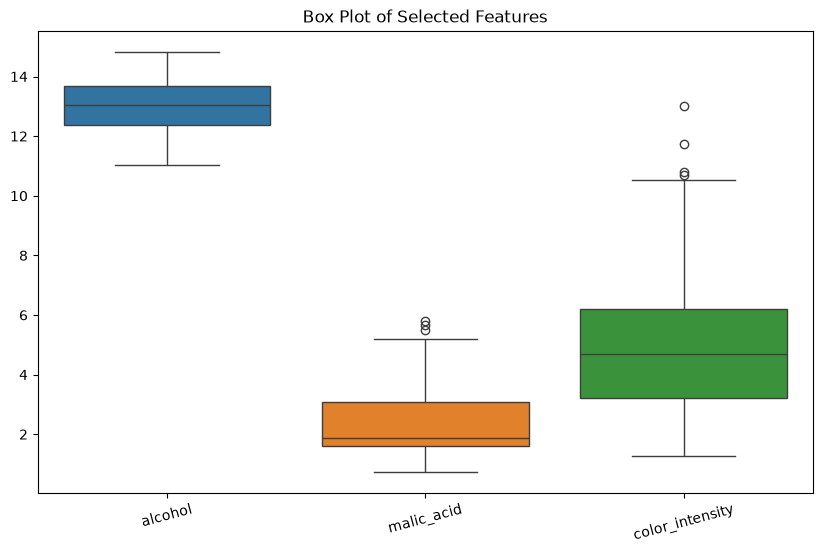

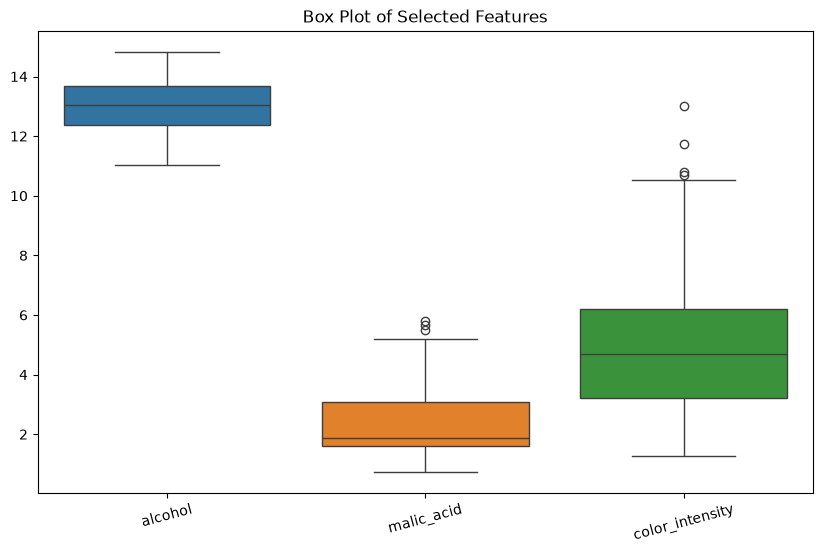

In [16]:

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[selected_features])

plt.title("Box Plot of Selected Features")
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[selected_features])

plt.title("Box Plot of Selected Features")
plt.xticks(rotation=15)
plt.show()


**Observation:** Points outside the whiskers may indicate potential outliers that need further investigation.

## Q4. Data Preprocessing

Prepare the dataset by:

    Separating features (X) and target (y)
    Splitting the data into 80% training and 20% testing sets using random_state=42
    Explain whether feature scaling is required for a Decision Tree Classifier.

In [17]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns="target")
y = df["target"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)


Training Data Shape: (142, 13)
Testing Data Shape: (36, 13)


**Explanation:**  Feature scaling is generally not required for a Decision Tree Classifier because it makes decisions using feature thresholds rather than distance calculations.

## Q5. Model Training

Build a Decision Tree Classifier using the training dataset and:

    Train the model
    Display the tree depth
    Display the number of leaf nodes
    Visualize the Decision Tree

In [18]:

from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [19]:

model.get_depth()


4

In [20]:
 model.get_n_leaves()

np.int64(8)

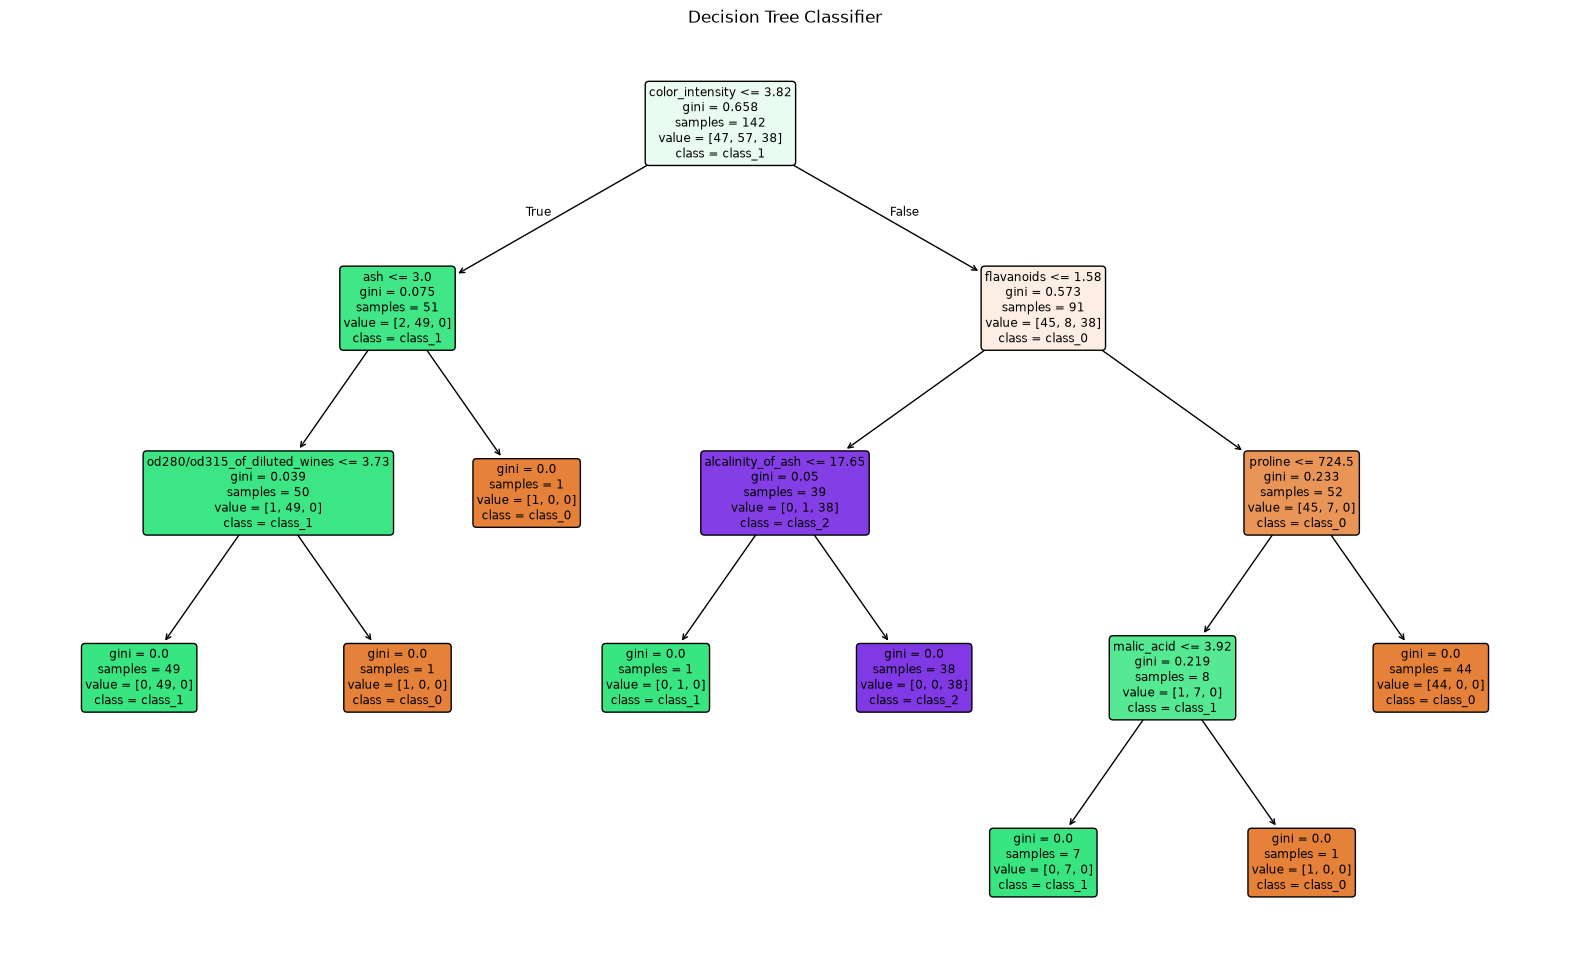

In [21]:

from sklearn.tree import plot_tree

plt.figure(figsize=(20, 12))

plot_tree(
    model,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree Classifier")
plt.show()


## Q6. Prediction

Predict the target classes for the testing dataset and display a comparison of the Actual and Predicted values.

In [22]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("Actual vs Predicted Values:")
print(comparison.to_string(index=False))


Actual vs Predicted Values:
 Actual  Predicted
      0          0
      2          1
      0          0
      1          1
      1          1
      0          0
      0          0
      1          1
      1          1
      2          2
      1          1
      2          2
      0          0
      2          2
      0          0
      1          1
      1          1
      0          0
      1          1
      0          1
      1          1
      1          1
      0          0
      0          0
      1          1
      1          1
      0          0
      2          2
      1          1
      2          2
      0          0
      2          2
      1          1
      2          2
      2          2
      2          2


## Q7. Model Evaluation

Evaluate the model using:

    Accuracy Score
    Precision Score
    Recall Score
    F1-Score
    Confusion Matrix
    Classification Report
    Interpret the results.

In [25]:


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy Score:", accuracy_score(y_test, y_pred))



Accuracy Score: 0.9444444444444444


In [26]:
print("Precision Score:",
      precision_score(y_test, y_pred, average="weighted"))



Precision Score: 0.9513888888888888


In [27]:

print("Recall Score:",
      recall_score(y_test, y_pred, average="weighted"))


Recall Score: 0.9444444444444444


In [28]:

print("F1-Score:",
      f1_score(y_test, y_pred, average="weighted"))



F1-Score: 0.9449614374099499


In [29]:

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))




Confusion Matrix:
[[11  1  0]
 [ 0 14  0]
 [ 0  1  9]]


In [31]:


print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=wine.target_names
))



Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



 **interpretation:** Higher evaluation scores generally indicate better classification performance. The confusion matrix helps identify which wine classes the model confuses with one another.

# Q8. Feature Importance

Display the feature importance scores and identify the top five most important features. Explain how these features contribute to the classification.

                     Feature  Importance
                  flavanoids    0.408073
             color_intensity    0.400189
                     proline    0.110985
od280/od315_of_diluted_wines    0.020986
           alcalinity_of_ash    0.020865
                         ash    0.020163
                  malic_acid    0.018738
                   magnesium    0.000000
                     alcohol    0.000000
             proanthocyanins    0.000000
        nonflavanoid_phenols    0.000000
               total_phenols    0.000000
                         hue    0.000000
                     Feature  Importance
                  flavanoids    0.408073
             color_intensity    0.400189
                     proline    0.110985
od280/od315_of_diluted_wines    0.020986
           alcalinity_of_ash    0.020865


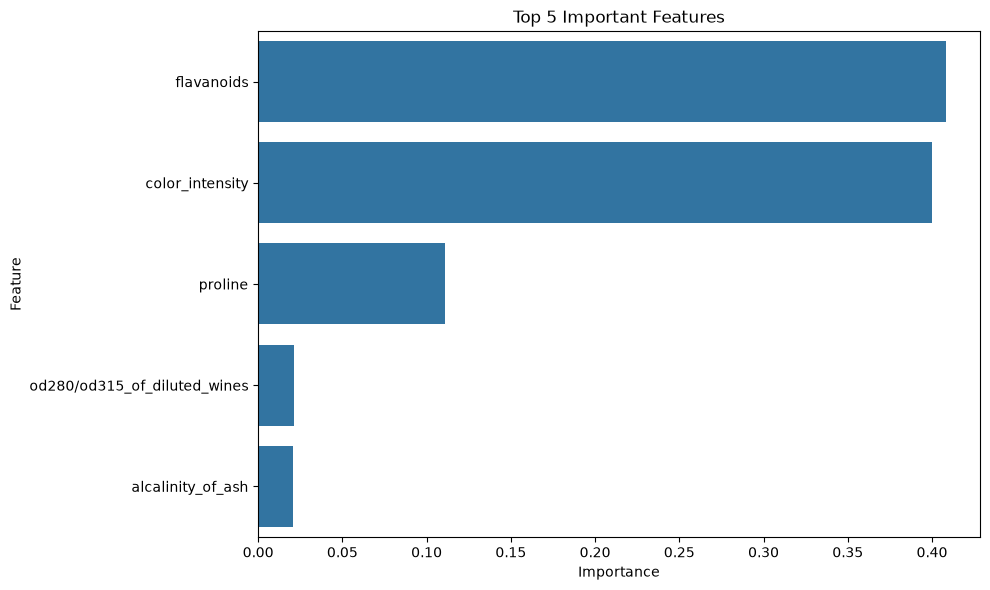

In [32]:



importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)


print(importance_df.to_string(index=False))


print(importance_df.head(5).to_string(index=False))


plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(5),
    x="Importance",
    y="Feature"
)

plt.title("Top 5 Important Features")
plt.tight_layout()
plt.show()


**Explanation:** The feature_importances_ attribute calculates the relative importance of each feature in the trained Decision Tree. The features are sorted in descending order, and the top five are displayed.

## Q9. Hyperparameter Tuning

Train another Decision Tree model by changing parameters such as:

    max_depth
    criterion (gini or entropy)
    min_samples_split
    Compare the performance of both models and discuss the results.

In [33]:

original_model = DecisionTreeClassifier(random_state=42)
original_model.fit(X_train, y_train)

original_pred = original_model.predict(X_test)


tuned_model = DecisionTreeClassifier(
    max_depth=4,
    criterion="entropy",
    min_samples_split=5,
    random_state=42
)

tuned_model.fit(X_train, y_train)

tuned_pred = tuned_model.predict(X_test)


results = pd.DataFrame({
    "Model": ["Original Model", "Tuned Model"],
    "Accuracy": [
        accuracy_score(y_test, original_pred),
        accuracy_score(y_test, tuned_pred)
    ],
    "Precision": [
        precision_score(
            y_test, original_pred, average="weighted"
        ),
        precision_score(
            y_test, tuned_pred, average="weighted"
        )
    ],
    "Recall": [
        recall_score(
            y_test, original_pred, average="weighted"
        ),
        recall_score(
            y_test, tuned_pred, average="weighted"
        )
    ],
    "F1-Score": [
        f1_score(
            y_test, original_pred, average="weighted"
        ),
        f1_score(
            y_test, tuned_pred, average="weighted"
        )
    ]
})


print(results.to_string(index=False))


         Model  Accuracy  Precision   Recall  F1-Score
Original Model  0.944444   0.951389 0.944444  0.944961
   Tuned Model  0.972222   0.974074 0.972222  0.971970


## Q10. Conclusion

Write a short report that includes:

    Overall model performance
    Advantages and limitations of Decision Tree Classifier
    Overfitting analysis
    Two real-world applications of Decision Tree Classification

## Conclusion: Decision Tree Classifier

**1. Overall Model Performance**

The Decision Tree Classifier was trained using the Scikit-learn Wine Dataset. The model predicted wine classes and was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. The performance metrics help assess how correctly the model classifies wine samples.

**2. Advantages of Decision Tree Classifier**

- Easy to understand and interpret.
- Handles classification tasks effectively.
- Does not generally require feature scaling.
- Can capture nonlinear relationships between features.

**3. Limitations of Decision Tree Classifier**

- May overfit the training data.
- Small changes in data can produce a different tree.
- A deep tree can become complex and generalize poorly.

**4. Overfitting Analysis**

Overfitting occurs when a model learns the training data too closely and performs poorly on unseen data. Parameters such as `max_depth` and `min_samples_split` can help control tree complexity. Comparing training and testing performance helps identify possible overfitting.

**5. Real-World Applications**

- **Medical diagnosis:** Classifying patients into risk or diagnostic categories based on relevant features.
- **Banking:** Classifying loan applications into risk categories using applicant information.

**Final Conclusion**

The Decision Tree Classifier is a useful and interpretable machine learning algorithm for classification. Hyperparameter tuning can help control overfitting and improve generalization. The final model should be selected based on its measured performance on unseen testing data.